In [1]:
import pandas as pd 
file_path="/Users/vaibhav/Desktop/AI_project/intelligent-crop-recommendation/ml-engine/datasets/raw/groundwater/Ground_Water_Level_Manual_Monthly_Karnataka_2021_2025.csv"

df=pd.read_csv(file_path)

/var/folders/n4/dnm1dzgn3xs3d7lv557mflcc0000gn/T/ipykernel_1663/1928307823.py:4: DtypeWarning: Columns (11: Basin Code) have mixed types. Specify dtype option on import or set low_memory=False.
  df=pd.read_csv(file_path)


In [2]:
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())

display(df.dtypes)
display(df.isnull().sum())
display(df.describe(include="all"))

Shape: (124384, 18)
Columns: ['_id', 'Station Code', 'State', 'State Code', 'District', 'District Code', 'Block', 'Block Code', 'GP Name', 'GP Code', 'Basin', 'Basin Code', 'Sub Basin', 'Sub Basin Code', 'Latitude', 'Longitude', 'Monitoring Date', 'Ground Water Level']


_id                     int64
Station Code              str
State                     str
State Code              int64
District                  str
District Code           int64
Block                     str
Block Code              int64
GP Name                   str
GP Code                   str
Basin                     str
Basin Code             object
Sub Basin                 str
Sub Basin Code        float64
Latitude              float64
Longitude             float64
Monitoring Date           str
Ground Water Level    float64
dtype: object

_id                       0
Station Code              0
State                     0
State Code                0
District                  0
District Code             0
Block                     0
Block Code                0
GP Name                   0
GP Code                   0
Basin                     0
Basin Code                0
Sub Basin                 0
Sub Basin Code        27971
Latitude                119
Longitude               136
Monitoring Date           0
Ground Water Level        0
dtype: int64

,_id,Station Code,State,State Code,District,District Code,Block,Block Code,GP Name,GP Code,Basin,Basin Code,Sub Basin,Sub Basin Code,Latitude,Longitude,Monitoring Date,Ground Water Level
count,124384.000000,124384,124384,124384.0,124384,124384.000000,124384,124384.000000,124384,124384,124384,124384,124384,96413.000000,124265.000000,124248.000000,124384,124384.000000
unique,NaN,2709,1,NaN,31,NaN,236,NaN,1268,1335,7,10,21,NaN,NaN,NaN,60,NaN
top,NaN,10101,Karnataka,NaN,Chitradurga,NaN,Challakere,NaN,-,-,Krishna,7,-,NaN,NaN,NaN,01-01-2024,NaN
freq,NaN,60,124384,NaN,8887,NaN,2244,NaN,58730,58730,62297,41803,27971,NaN,NaN,NaN,2709,NaN
mean,62192.500000,NaN,NaN,10.0,NaN,198.042602,NaN,272.093123,NaN,NaN,NaN,NaN,NaN,140.383392,14.218974,76.256798,NaN,15.237637
std,35906.712279,NaN,NaN,0.0,NaN,89.575248,NaN,673.539185,NaN,NaN,NaN,NaN,NaN,100.248647,1.487290,2.525742,NaN,22.190199
min,1.000000,NaN,NaN,10.0,NaN,164.000000,NaN,1.000000,NaN,NaN,NaN,NaN,NaN,20.000000,4.300000,13.042780,NaN,-0.500000
25%,31096.750000,NaN,NaN,10.0,NaN,172.000000,NaN,52.000000,NaN,NaN,NaN,NaN,NaN,23.000000,13.119400,75.629000,NaN,4.200000
50%,62192.500000,NaN,NaN,10.0,NaN,179.000000,NaN,95.000000,NaN,NaN,NaN,NaN,NaN,226.000000,13.848112,76.317286,NaN,8.850000
75%,93288.250000,NaN,NaN,10.0,NaN,187.000000,NaN,148.000000,NaN,NaN,NaN,NaN,NaN,229.000000,15.315600,77.083260,NaN,17.100000


In [3]:
# Work on a copy; preserve the original dataset
df_clean = df.copy()

# Inspect actual date examples first
print(df_clean["Monitoring Date"].head(15).tolist())

# Convert dates (assuming DD-MM-YYYY format)
df_clean["Monitoring Date"] = pd.to_datetime(
    df_clean["Monitoring Date"],
    format="%d-%m-%Y",
    errors="coerce"
)

print("Date conversion failures:",
      df_clean["Monitoring Date"].isna().sum())

print("Earliest date:", df_clean["Monitoring Date"].min())
print("Latest date:", df_clean["Monitoring Date"].max())

print("Unique monitoring dates:",
      df_clean["Monitoring Date"].nunique())

['01-01-2021', '01-02-2021', '01-03-2021', '01-04-2021', '01-05-2021', '01-06-2021', '01-07-2021', '01-08-2021', '01-09-2021', '01-10-2021', '01-11-2021', '01-12-2021', '01-01-2022', '01-02-2022', '01-03-2022']
Date conversion failures: 0
Earliest date: 2021-01-01 00:00:00
Latest date: 2025-12-01 00:00:00
Unique monitoring dates: 60


In [4]:
station_frequency = (
    df_clean.groupby("Station Code")
    .agg(
        total_records=("Ground Water Level", "count"),
        unique_dates=("Monitoring Date", "nunique"),
        first_observation=("Monitoring Date", "min"),
        last_observation=("Monitoring Date", "max")
    )
    .reset_index()
)

display(station_frequency.head(10))

print("Total stations:", len(station_frequency))

print("\nRecords per station:")
display(station_frequency["total_records"].describe())

,Station Code,total_records,unique_dates,first_observation,last_observation
0,010801D,58,58,2021-01-01,2025-10-01
1,020109b,60,60,2021-01-01,2025-12-01
2,020116a,60,60,2021-01-01,2025-12-01
3,020203A,60,60,2021-01-01,2025-12-01
4,020204C,24,24,2024-01-01,2025-12-01
5,020206A,60,60,2021-01-01,2025-12-01
6,020402a,60,60,2021-01-01,2025-12-01
7,020405a,60,60,2021-01-01,2025-12-01
8,020408A,60,60,2021-01-01,2025-12-01
9,020503A,60,60,2021-01-01,2025-12-01


Total stations: 2709

Records per station:


count    2709.000000
mean       45.915098
std        16.295672
min        12.000000
25%        24.000000
50%        56.000000
75%        60.000000
max        60.000000
Name: total_records, dtype: float64

In [5]:
duplicates = df_clean.duplicated(
    subset=["Station Code", "Monitoring Date"],
    keep=False
)
print(duplicates)
print("Duplicate station-date records:", duplicates.sum())

display(
    df_clean.loc[
        duplicates,
        ["Station Code", "Monitoring Date", "Ground Water Level"]
    ].head(20)
)

0         False
1         False
2         False
3         False
4         False
          ...  
124379    False
124380    False
124381    False
124382    False
124383    False
Length: 124384, dtype: bool
Duplicate station-date records: 0


,Station Code,Monitoring Date,Ground Water Level


In [6]:
print("Groundwater level statistics:")

display(
    df_clean["Ground Water Level"].describe(
        percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
    )
)

print("Negative readings:",
      (df_clean["Ground Water Level"] < 0).sum())

print("Readings above 100 metres:",
      (df_clean["Ground Water Level"] > 100).sum())

Groundwater level statistics:


count    124384.000000
mean         15.237637
std          22.190199
min          -0.500000
1%           -0.050000
5%            1.000000
25%           4.200000
50%           8.850000
75%          17.100000
95%          50.630000
99%         116.671700
max         301.300000
Name: Ground Water Level, dtype: float64

Negative readings: 2726
Readings above 100 metres: 1750


In [7]:
def find_missing_months(group):

    # Find the first and last observation dates
    start_date = group["Monitoring Date"].min()
    end_date = group["Monitoring Date"].max()

    # Generate all expected monthly periods
    expected_months = pd.period_range(
        start=start_date,
        end=end_date,
        freq="M"
    )

    # Get months actually present
    actual_months = group["Monitoring Date"].dt.to_period("M").unique()

    # Identify missing months
    missing = expected_months.difference(actual_months)

    return len(missing)


# Calculate missing months for every station
missing_analysis = (
    df_clean.groupby("Station Code")
    .apply(find_missing_months)
    .reset_index(name="missing_months")
)

display(missing_analysis.head(10))

print("Stations with missing months:",
      (missing_analysis["missing_months"] > 0).sum())

print("Total missing station-month observations:",
      missing_analysis["missing_months"].sum())

,Station Code,missing_months
0,010801D,0
1,020109b,0
2,020116a,0
3,020203A,0
4,020204C,0
5,020206A,0
6,020402a,0
7,020405a,0
8,020408A,0
9,020503A,0


Stations with missing months: 262
Total missing station-month observations: 1373


In [8]:
# Inspect negative readings
negative_records = df_clean[
    df_clean["Ground Water Level"] < 0
]

display(
    negative_records[
        [
            "Station Code",
            "District",
            "Block",
            "Monitoring Date",
            "Ground Water Level"
        ]
    ].head(20)
)

# Inspect readings above 100 metres
high_records = df_clean[
    df_clean["Ground Water Level"] > 100
]

display(
    high_records[
        [
            "Station Code",
            "District",
            "Block",
            "Monitoring Date",
            "Ground Water Level"
        ]
    ].head(20)
)

,Station Code,District,Block,Monitoring Date,Ground Water Level
1224,10311,Bengaluru Urban,Bengaluru South,2024-04-01,-0.05
1225,10311,Bengaluru Urban,Bengaluru South,2024-05-01,-0.05
1443,10319,Bengaluru Urban,Bengaluru South,2024-01-01,-0.05
1467,10320,Bengaluru Urban,Bengaluru South,2024-01-01,-0.05
1491,10321,Bengaluru Urban,Bengaluru South,2024-01-01,-0.05
1492,10321,Bengaluru Urban,Bengaluru South,2024-02-01,-0.05
1493,10321,Bengaluru Urban,Bengaluru South,2024-03-01,-0.05
1494,10321,Bengaluru Urban,Bengaluru South,2024-04-01,-0.05
1495,10321,Bengaluru Urban,Bengaluru South,2024-05-01,-0.05
6540,10827,Ramanagara,Kanakapura,2024-03-01,-0.05


,Station Code,District,Block,Monitoring Date,Ground Water Level
2460,10514,Bengaluru Rural,Devanahalli,2024-03-01,151.385
2461,10514,Bengaluru Rural,Devanahalli,2024-04-01,143.110
2527,10516,Bengaluru Rural,Devanahalli,2022-03-01,244.000
2528,10516,Bengaluru Rural,Devanahalli,2022-05-01,190.000
2529,10516,Bengaluru Rural,Devanahalli,2022-10-01,190.870
2530,10516,Bengaluru Rural,Devanahalli,2022-11-01,185.620
2531,10516,Bengaluru Rural,Devanahalli,2022-12-01,182.340
2534,10516,Bengaluru Rural,Devanahalli,2023-04-01,151.160
2535,10516,Bengaluru Rural,Devanahalli,2023-05-01,146.190
2536,10516,Bengaluru Rural,Devanahalli,2023-06-01,155.440


In [9]:
# Count each negative groundwater value
negative_value_counts = (
    df_clean[df_clean["Ground Water Level"] < 0]
    ["Ground Water Level"]
    .value_counts()
    .sort_index()
)

display(negative_value_counts)

# Find stations that contain negative readings
negative_station_summary = (
    df_clean[df_clean["Ground Water Level"] < 0]
    .groupby(["Station Code", "District", "Block"])
    .agg(
        negative_records=("Ground Water Level", "count"),
        first_negative_date=("Monitoring Date", "min"),
        last_negative_date=("Monitoring Date", "max")
    )
    .reset_index()
    .sort_values("negative_records", ascending=False)
)

display(negative_station_summary.head(20))

print("Stations with negative readings:",
      len(negative_station_summary))

Ground Water Level
-0.50       1
-0.30       1
-0.27       1
-0.17       1
-0.15       1
-0.13       1
-0.05    2720
Name: count, dtype: int64

,Station Code,District,Block,negative_records,first_negative_date,last_negative_date
262,60610,Chikkamagaluru,Sringeri,24,2024-01-01,2025-12-01
260,60309,Chikkamagaluru,Koppa,24,2024-01-01,2025-12-01
6,091716HP,Gadag,Lakshmeshwar,24,2024-01-01,2025-12-01
266,60802,Chikkamagaluru,Kalasa,24,2024-01-01,2025-12-01
244,50606,Bagalkot,Ilkal,19,2022-02-01,2024-08-01
147,150803D,Mysuru,Nanjangud,12,2024-01-01,2024-12-01
137,150707D,Mysuru,Mysuru,12,2024-01-01,2024-12-01
138,150708,Mysuru,Mysuru,12,2024-01-01,2024-12-01
139,150710,Mysuru,Mysuru,12,2024-01-01,2024-12-01
140,150713D,Mysuru,Mysuru,12,2024-01-01,2024-12-01


Stations with negative readings: 316


In [10]:
# Find stations with readings above 100 metres
high_station_summary = (
    df_clean[df_clean["Ground Water Level"] > 100]
    .groupby(["Station Code", "District", "Block"])
    .agg(
        high_records=("Ground Water Level", "count"),
        minimum_level=("Ground Water Level", "min"),
        maximum_level=("Ground Water Level", "max"),
        first_date=("Monitoring Date", "min"),
        last_date=("Monitoring Date", "max")
    )
    .reset_index()
    .sort_values("high_records", ascending=False)
)

display(high_station_summary.head(20))

print("Stations with readings above 100 metres:",
      len(high_station_summary))

,Station Code,District,Block,high_records,minimum_level,maximum_level,first_date,last_date
119,131120,Kolar,Srinivaspur,60,137.30,243.35,2021-01-01,2025-12-01
85,130812,Kolar,Malur,60,150.60,265.70,2021-01-01,2025-12-01
87,130815,Kolar,Malur,59,104.45,227.22,2021-01-01,2025-12-01
83,130805,Kolar,Malur,41,101.32,177.33,2021-01-01,2025-12-01
120,131121,Kolar,Srinivaspur,40,103.30,160.50,2021-03-01,2025-12-01
6,10523,Bengaluru Rural,Devanahalli,40,103.61,222.00,2022-02-01,2025-12-01
5,10522,Bengaluru Rural,Devanahalli,39,102.02,239.00,2022-02-01,2025-12-01
8,10525,Bengaluru Rural,Devanahalli,39,148.99,234.00,2022-02-01,2025-12-01
11,10529,Bengaluru Rural,Devanahalli,39,157.51,221.00,2022-03-01,2025-12-01
2,10516,Bengaluru Rural,Devanahalli,38,104.42,244.00,2022-03-01,2025-12-01


Stations with readings above 100 metres: 137


In [11]:
print(high_station_summary.columns)
print(high_station_summary.head())

Index(['Station Code', 'District', 'Block', 'high_records', 'minimum_level',
       'maximum_level', 'first_date', 'last_date'],
      dtype='str')
    Station Code District        Block  high_records  minimum_level  \
119       131120    Kolar  Srinivaspur            60         137.30   
85        130812    Kolar        Malur            60         150.60   
87        130815    Kolar        Malur            59         104.45   
83        130805    Kolar        Malur            41         101.32   
120       131121    Kolar  Srinivaspur            40         103.30   

     maximum_level first_date  last_date  
119         243.35 2021-01-01 2025-12-01  
85          265.70 2021-01-01 2025-12-01  
87          227.22 2021-01-01 2025-12-01  
83          177.33 2021-01-01 2025-12-01  
120         160.50 2021-03-01 2025-12-01  


Matplotlib is building the font cache; this may take a moment.


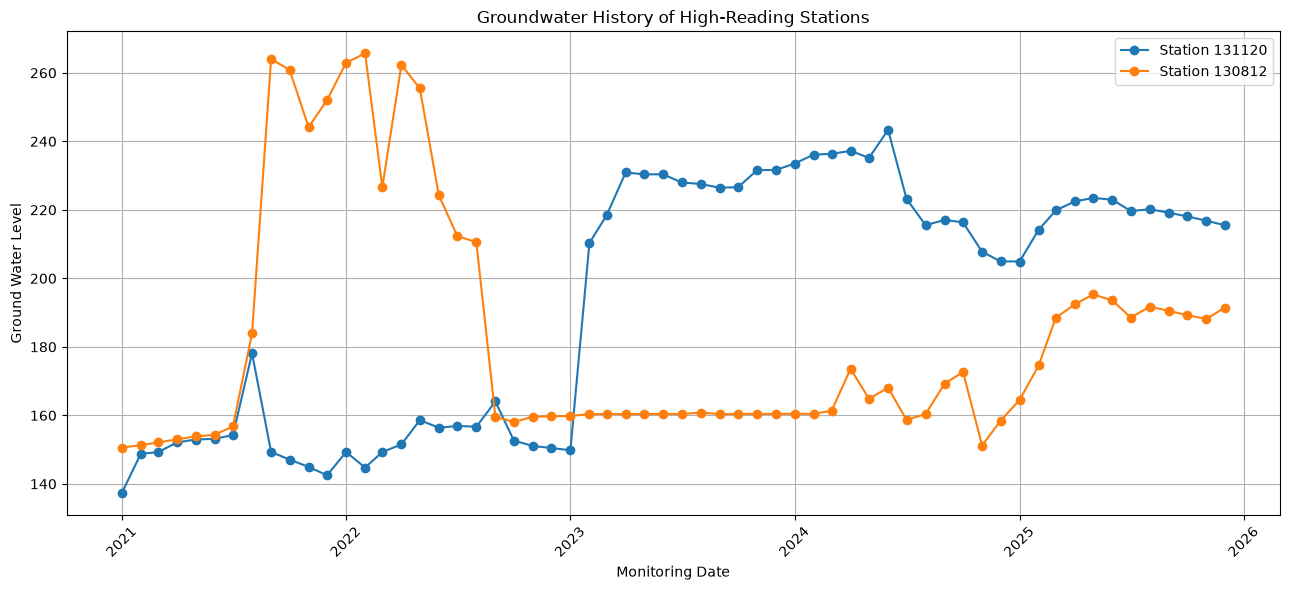

In [13]:
import matplotlib.pyplot as plt
# Select two stations with many high readings
selected_stations = ["131120", "130812"]

plt.figure(figsize=(13, 6))

for code in selected_stations:

    station_data = (
        df_clean[df_clean["Station Code"].astype(str) == code]
        .sort_values("Monitoring Date")
    )

    plt.plot(
        station_data["Monitoring Date"],
        station_data["Ground Water Level"],
        marker="o",
        label=f"Station {code}"
    )

plt.title("Groundwater History of High-Reading Stations")
plt.xlabel("Monitoring Date")
plt.ylabel("Ground Water Level")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [14]:
identify_station=df_clean[ df_clean["Station Code"].astype(str)=="130812"].sort_values(by="Monitoring Date")["Ground Water Level"].value_counts().head(10)

In [15]:
print(identify_station)

Ground Water Level
160.38    3
160.37    2
160.41    2
160.43    2
150.60    1
151.30    1
152.10    1
153.00    1
153.85    1
154.32    1
Name: count, dtype: int64


In [16]:
station_130812 = df_clean[
    df_clean["Station Code"].astype(str) == "130812"
].loc[:, ["Ground Water Level", "Monitoring Date"]].sort_values(by="Monitoring Date")

print(station_130812)

       Ground Water Level Monitoring Date
81782              150.60      2021-01-01
81783              151.30      2021-02-01
81784              152.10      2021-03-01
81785              153.00      2021-04-01
81786              153.85      2021-05-01
81787              154.32      2021-06-01
81788              156.80      2021-07-01
81789              184.00      2021-08-01
81790              264.00      2021-09-01
81791              260.91      2021-10-01
81792              244.12      2021-11-01
81793              252.05      2021-12-01
81794              262.92      2022-01-01
81795              265.70      2022-02-01
81796              226.60      2022-03-01
81797              262.29      2022-04-01
81798              255.50      2022-05-01
81799              224.21      2022-06-01
81800              212.37      2022-07-01
81801              210.56      2022-08-01
81802              159.58      2022-09-01
81803              158.06      2022-10-01
81804              159.60      202

In [ ]:
print(len(station_130812))

60


In [17]:
#calculating the diff between consecutive level

station_130812["level_change"]=station_130812["Ground Water Level"].diff()

In [18]:
print(station_130812)

       Ground Water Level Monitoring Date  level_change
81782              150.60      2021-01-01           NaN
81783              151.30      2021-02-01          0.70
81784              152.10      2021-03-01          0.80
81785              153.00      2021-04-01          0.90
81786              153.85      2021-05-01          0.85
81787              154.32      2021-06-01          0.47
81788              156.80      2021-07-01          2.48
81789              184.00      2021-08-01         27.20
81790              264.00      2021-09-01         80.00
81791              260.91      2021-10-01         -3.09
81792              244.12      2021-11-01        -16.79
81793              252.05      2021-12-01          7.93
81794              262.92      2022-01-01         10.87
81795              265.70      2022-02-01          2.78
81796              226.60      2022-03-01        -39.10
81797              262.29      2022-04-01         35.69
81798              255.50      2022-05-01       

In [19]:
largest_changes=station_130812["level_change"].abs().nlargest(10)
print(largest_changes)

81790    80.00
81802    50.98
81796    39.10
81797    35.69
81799    31.29
81789    27.20
81828    21.45
81792    16.79
81832    13.89
81821    12.24
Name: level_change, dtype: float64


In [20]:
sudden_ground_water_change=station_130812.loc[largest_changes.index]

In [21]:
print(sudden_ground_water_change)

       Ground Water Level Monitoring Date  level_change
81790              264.00      2021-09-01         80.00
81802              159.58      2022-09-01        -50.98
81796              226.60      2022-03-01        -39.10
81797              262.29      2022-04-01         35.69
81799              224.21      2022-06-01        -31.29
81789              184.00      2021-08-01         27.20
81828              151.20      2024-11-01        -21.45
81792              244.12      2021-11-01        -16.79
81832              188.48      2025-03-01         13.89
81821              173.58      2024-04-01         12.24


In [22]:
station_130812["absolute_change"] = station_130812["level_change"].abs()
mean_change = station_130812["absolute_change"].mean()
print("Mean absolute change:", mean_change)
max_change = station_130812["absolute_change"].max()
print("Maximum absolute change:", max_change)
large_change_count = (
    station_130812["absolute_change"] > 10
).sum()

print("Months with changes > 10 metres:", large_change_count)


Mean absolute change: 7.937288135593221
Maximum absolute change: 80.0
Months with changes > 10 metres: 13


In [23]:
#Does same with another 
station_130815 = df_clean[
    df_clean["Station Code"].astype(str) == "130815"
][["Monitoring Date", "Ground Water Level"]].sort_values(
    by="Monitoring Date"
)
station_130815["level_change"] = (
    station_130815["Ground Water Level"].diff()
)

station_130815["absolute_change"] = (
    station_130815["level_change"].abs()
)

display(station_130815)

largest_changes_130815 = (
    station_130815["absolute_change"].nlargest(10)
)

display(
    station_130815.loc[largest_changes_130815.index]
)

,Monitoring Date,Ground Water Level,level_change,absolute_change
81941,2021-01-01,106.90,NaN,NaN
81942,2021-02-01,105.40,-1.50,1.50
81943,2021-03-01,105.93,0.53,0.53
81944,2021-04-01,104.45,-1.48,1.48
81945,2021-05-01,106.40,1.95,1.95
81946,2021-06-01,108.75,2.35,2.35
81947,2021-07-01,117.65,8.90,8.90
81948,2021-08-01,138.90,21.25,21.25
81949,2021-09-01,203.30,64.40,64.40
81950,2021-10-01,201.81,-1.49,1.49


,Monitoring Date,Ground Water Level,level_change,absolute_change
81976,2023-12-01,221.84,200.20,200.20
81975,2023-11-01,21.64,-194.37,194.37
81953,2022-01-01,138.90,-67.54,67.54
81949,2021-09-01,203.30,64.40,64.40
81952,2021-12-01,206.44,61.19,61.19
81966,2023-02-01,216.05,59.86,59.86
81951,2021-11-01,145.25,-56.56,56.56
81948,2021-08-01,138.90,21.25,21.25
81955,2022-03-01,149.25,18.22,18.22
81983,2024-07-01,210.37,-15.57,15.57


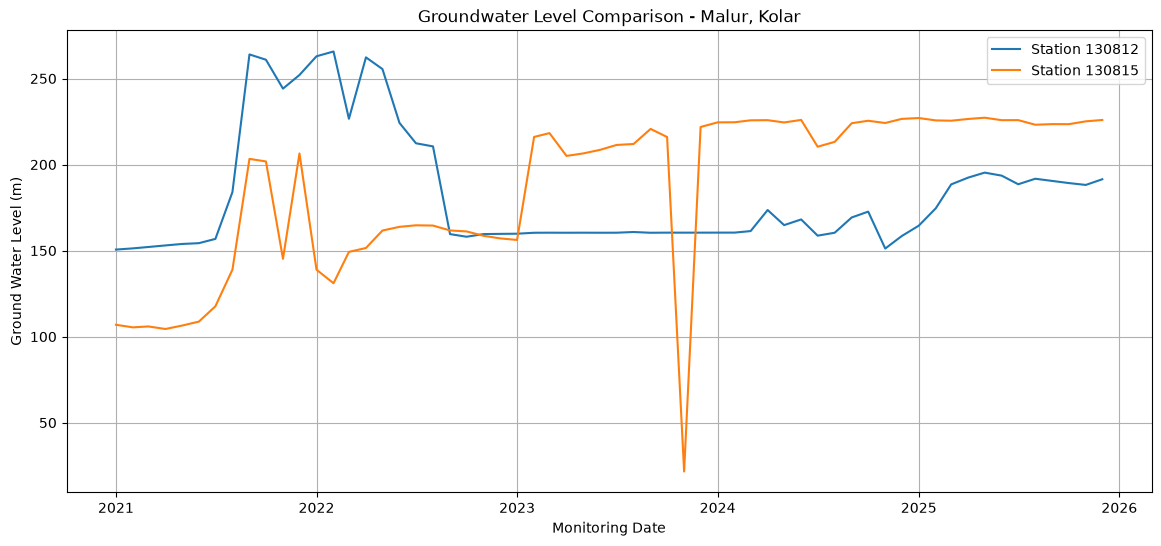

In [24]:
plt.figure(figsize=(14, 6))

plt.plot(
    station_130812["Monitoring Date"],
    station_130812["Ground Water Level"],
    label="Station 130812"
)

plt.plot(
    station_130815["Monitoring Date"],
    station_130815["Ground Water Level"],
    label="Station 130815"
)

plt.xlabel("Monitoring Date")
plt.ylabel("Ground Water Level (m)")
plt.title("Groundwater Level Comparison - Malur, Kolar")
plt.legend()
plt.grid(True)
plt.show()


In [27]:
min_index = station_130815["Ground Water Level"].idxmin()
print(station_130815.loc[min_index])

Monitoring Date       2023-11-01 00:00:00
Ground Water Level                  21.64
level_change                      -194.37
absolute_change                    194.37
Name: 81975, dtype: object


In [28]:
position = station_130815.index.get_loc(min_index)

display(
    station_130815.iloc[
        max(0, position - 2):position + 3
    ]
)

,Monitoring Date,Ground Water Level,level_change,absolute_change
81973,2023-09-01,220.71,8.76,8.76
81974,2023-10-01,216.01,-4.70,4.70
81975,2023-11-01,21.64,-194.37,194.37
81976,2023-12-01,221.84,200.20,200.20
81977,2024-01-01,224.52,2.68,2.68


In [33]:
suspicious_record = df_clean[
    (df_clean["Station Code"].astype(str) == "130815") &
    (df_clean["Monitoring Date"] == "2023-11-01")
]

display(suspicious_record.T)

,81975
_id,81976
Station Code,130815
State,Karnataka
State Code,10
District,Kolar
District Code,182
Block,Malur
Block Code,106
GP Name,Thornahalli
GP Code,6468


In [52]:
#getting only mular block
mular_block=df_clean[(df_clean['Block'].astype(str)=="Malur") & 
                     (df_clean['District'].astype(str)=="Kolar") & 
                     (df_clean['Monitoring Date']==pd.Timestamp("2023-11-01") )]
mular_block=mular_block[["Station Code", "GP Name", "Monitoring Date", "Ground Water Level"]].sort_values(by="Ground Water Level")

In [53]:
print(mular_block)

      Station Code       GP Name Monitoring Date  Ground Water Level
81696       130810     D.N.Doddi      2023-11-01                1.60
81576       130808             -      2023-11-01                3.07
81344       130804         Masti      2023-11-01                5.38
81224       130802     Kudiyanur      2023-11-01                7.66
81516       130807             -      2023-11-01                8.65
81636       130809             -      2023-11-01               10.25
81164       130801             -      2023-11-01               12.43
81284       130803        Lakkur      2023-11-01               13.24
81915       130814      Nosagere      2023-11-01               14.66
81756       130811  Hungenahalli      2023-11-01               14.95
81456       130806             -      2023-11-01               17.03
81975       130815   Thornahalli      2023-11-01               21.64
81404       130805             -      2023-11-01               75.24
81855       130813             -  

In [59]:
#specific station with obersevation from oct to dec
specific_station=df_clean[(df_clean["Station Code"].astype(str)=="130815") & (df_clean["Monitoring Date"]>=pd.Timestamp("2023-10-01")) &
                           (df_clean['Monitoring Date']<=pd.Timestamp("2023-12-01"))][["Station Code", "GP Name", "Monitoring Date", "Ground Water Level"]]


In [60]:
print(specific_station)

      Station Code      GP Name Monitoring Date  Ground Water Level
81974       130815  Thornahalli      2023-10-01              216.01
81975       130815  Thornahalli      2023-11-01               21.64
81976       130815  Thornahalli      2023-12-01              221.84


In [63]:
specific_station["diff"]=specific_station["Ground Water Level"].diff()

In [64]:
print(specific_station)

      Station Code      GP Name Monitoring Date  Ground Water Level    diff
81974       130815  Thornahalli      2023-10-01              216.01     NaN
81975       130815  Thornahalli      2023-11-01               21.64 -194.37
81976       130815  Thornahalli      2023-12-01              221.84  200.20


In [79]:
station_130815_history=df_clean[df_clean["Station Code"].astype(str)=="130815"][["Monitoring Date","Ground Water Level"]].sort_values(by="Monitoring Date")

In [80]:
print(station_130815_history)


      Monitoring Date  Ground Water Level
81941      2021-01-01              106.90
81942      2021-02-01              105.40
81943      2021-03-01              105.93
81944      2021-04-01              104.45
81945      2021-05-01              106.40
81946      2021-06-01              108.75
81947      2021-07-01              117.65
81948      2021-08-01              138.90
81949      2021-09-01              203.30
81950      2021-10-01              201.81
81951      2021-11-01              145.25
81952      2021-12-01              206.44
81953      2022-01-01              138.90
81954      2022-02-01              131.03
81955      2022-03-01              149.25
81956      2022-04-01              151.52
81957      2022-05-01              161.66
81958      2022-06-01              163.80
81959      2022-07-01              164.70
81960      2022-08-01              164.55
81961      2022-09-01              161.70
81962      2022-10-01              161.15
81963      2022-11-01             

In [81]:
station_130815_history["Level change"]=station_130815_history["Ground Water Level"].diff()

In [83]:
print(station_130815_history)


      Monitoring Date  Ground Water Level  Level change
81941      2021-01-01              106.90           NaN
81942      2021-02-01              105.40         -1.50
81943      2021-03-01              105.93          0.53
81944      2021-04-01              104.45         -1.48
81945      2021-05-01              106.40          1.95
81946      2021-06-01              108.75          2.35
81947      2021-07-01              117.65          8.90
81948      2021-08-01              138.90         21.25
81949      2021-09-01              203.30         64.40
81950      2021-10-01              201.81         -1.49
81951      2021-11-01              145.25        -56.56
81952      2021-12-01              206.44         61.19
81953      2022-01-01              138.90        -67.54
81954      2022-02-01              131.03         -7.87
81955      2022-03-01              149.25         18.22
81956      2022-04-01              151.52          2.27
81957      2022-05-01              161.66       

In [86]:
largest_changes=station_130815_history["Level change"].abs().nlargest(10)

In [87]:
print(largest_changes)


81976    200.20
81975    194.37
81953     67.54
81949     64.40
81952     61.19
81966     59.86
81951     56.56
81948     21.25
81955     18.22
81983     15.57
Name: Level change, dtype: float64


In [88]:
largest_changes_rows=station_130815_history.loc[largest_changes.index]

In [89]:
largest_changes_rows[
    ["Monitoring Date", "Ground Water Level", "Level change"]
]

,Monitoring Date,Ground Water Level,Level change
81976,2023-12-01,221.84,200.20
81975,2023-11-01,21.64,-194.37
81953,2022-01-01,138.90,-67.54
81949,2021-09-01,203.30,64.40
81952,2021-12-01,206.44,61.19
81966,2023-02-01,216.05,59.86
81951,2021-11-01,145.25,-56.56
81948,2021-08-01,138.90,21.25
81955,2022-03-01,149.25,18.22
81983,2024-07-01,210.37,-15.57


In [90]:
station_130815_history[
    station_130815_history["Monitoring Date"].between(
        "2023-08-01", "2024-02-01"
    )
]

,Monitoring Date,Ground Water Level,Level change
81972,2023-08-01,211.95,0.57
81973,2023-09-01,220.71,8.76
81974,2023-10-01,216.01,-4.70
81975,2023-11-01,21.64,-194.37
81976,2023-12-01,221.84,200.20
81977,2024-01-01,224.52,2.68
81978,2024-02-01,224.58,0.06


In [92]:
malur_comparison = df_clean[
    (df_clean["District"] == "Kolar") &
    (df_clean["Block"] == "Malur") &
    (df_clean["Monitoring Date"].isin([
        pd.Timestamp("2023-10-01"),
        pd.Timestamp("2023-11-01"),
        pd.Timestamp("2023-12-01")
    ]))
][["Station Code", "GP Name", "Monitoring Date", "Ground Water Level"]]

In [93]:
print(malur_comparison)

      Station Code       GP Name Monitoring Date  Ground Water Level
81163       130801             -      2023-10-01               14.15
81164       130801             -      2023-11-01               12.43
81165       130801             -      2023-12-01               13.36
81223       130802     Kudiyanur      2023-10-01                9.42
81224       130802     Kudiyanur      2023-11-01                7.66
81225       130802     Kudiyanur      2023-12-01                9.55
81283       130803        Lakkur      2023-10-01               13.45
81284       130803        Lakkur      2023-11-01               13.24
81285       130803        Lakkur      2023-12-01               14.35
81343       130804         Masti      2023-10-01                4.19
81344       130804         Masti      2023-11-01                5.38
81345       130804         Masti      2023-12-01                6.45
81403       130805             -      2023-10-01               75.17
81404       130805             -  

In [94]:
# Extract month number from Monitoring Date
df_clean["Month"] = df_clean["Monitoring Date"].dt.month

# Display the first 5 rows
df_clean[["Monitoring Date", "Month"]].head()

,Monitoring Date,Month
0,2021-01-01,1
1,2021-02-01,2
2,2021-03-01,3
3,2021-04-01,4
4,2021-05-01,5


In [96]:
monthly_groundwater = df_clean.groupby("Month")["Ground Water Level"].mean()

print(monthly_groundwater)

Month
1     14.175202
2     15.990282
3     17.772334
4     18.710410
5     17.760890
6     16.682727
7     15.368321
8     14.234560
9     13.777817
10    12.613474
11    12.576546
12    13.179985
Name: Ground Water Level, dtype: float64


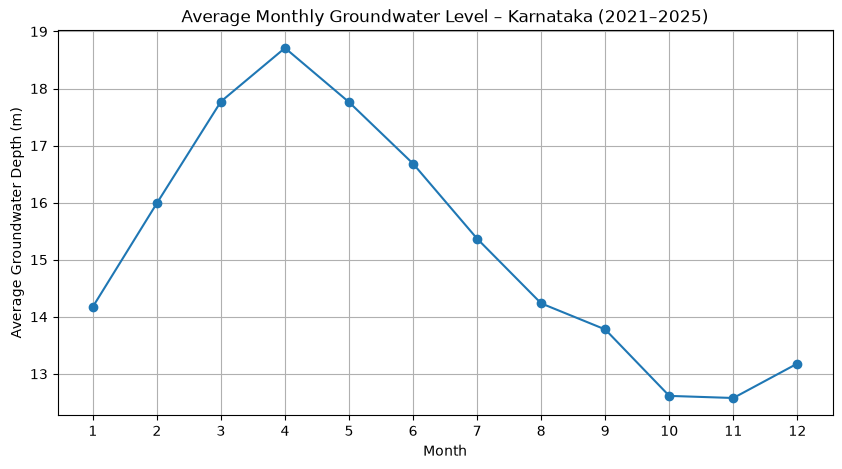

In [97]:
plt.figure(figsize=(10, 5))

plt.plot(
    monthly_groundwater.index,
    monthly_groundwater.values,
    marker="o"
)

plt.title("Average Monthly Groundwater Level – Karnataka (2021–2025)")
plt.xlabel("Month")
plt.ylabel("Average Groundwater Depth (m)")
plt.xticks(range(1, 13))
plt.grid(True)

plt.show()

In [98]:
monthly_median = df_clean.groupby("Month")[
    "Ground Water Level"
].median()

print(monthly_median)

Month
1      8.60
2      9.80
3     10.90
4     11.50
5     10.90
6     10.10
7      8.65
8      7.70
9      7.48
10     6.51
11     6.92
12     7.64
Name: Ground Water Level, dtype: float64


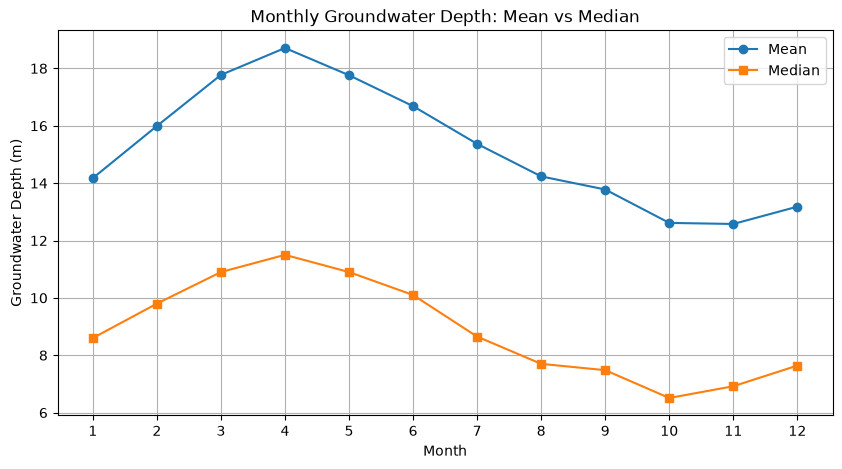

In [99]:
plt.figure(figsize=(10, 5))

plt.plot(monthly_groundwater.index, monthly_groundwater.values,
         marker="o", label="Mean")

plt.plot(monthly_median.index, monthly_median.values,
         marker="s", label="Median")

plt.title("Monthly Groundwater Depth: Mean vs Median")
plt.xlabel("Month")
plt.ylabel("Groundwater Depth (m)")
plt.xticks(range(1, 13))
plt.legend()
plt.grid(True)

plt.show()

In [100]:
season_mapping = {
    1: "Winter",
    2: "Winter",
    3: "Pre-Monsoon",
    4: "Pre-Monsoon",
    5: "Pre-Monsoon",
    6: "Monsoon",
    7: "Monsoon",
    8: "Monsoon",
    9: "Monsoon",
    10: "Post-Monsoon",
    11: "Post-Monsoon",
    12: "Post-Monsoon"
}

df_clean["Season"] = df_clean["Month"].map(season_mapping)

In [101]:
print(df_clean["Season"])

0               Winter
1               Winter
2          Pre-Monsoon
3          Pre-Monsoon
4          Pre-Monsoon
              ...     
124379         Monsoon
124380         Monsoon
124381    Post-Monsoon
124382    Post-Monsoon
124383    Post-Monsoon
Name: Season, Length: 124384, dtype: str


In [102]:
seasonal_groundwater = df_clean.groupby("Season")[
    "Ground Water Level"
].agg(["mean", "median", "min", "max", "count"])

print(seasonal_groundwater)

                   mean  median   min     max  count
Season                                              
Monsoon       15.013169    8.45 -0.50  301.30  41787
Post-Monsoon  12.788204    7.05 -0.30  292.36  30958
Pre-Monsoon   18.080778   11.10 -0.27  295.60  31077
Winter        15.084596    9.18 -0.05  294.40  20562


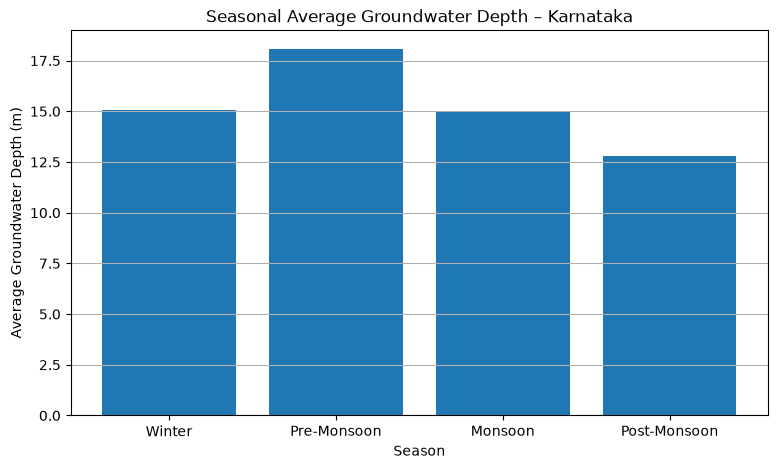

In [103]:
seasonal_mean = df_clean.groupby("Season")[
    "Ground Water Level"
].mean()

season_order = [
    "Winter",
    "Pre-Monsoon",
    "Monsoon",
    "Post-Monsoon"
]

seasonal_mean = seasonal_mean.reindex(season_order)

plt.figure(figsize=(9, 5))

plt.bar(seasonal_mean.index, seasonal_mean.values)

plt.title("Seasonal Average Groundwater Depth – Karnataka")
plt.xlabel("Season")
plt.ylabel("Average Groundwater Depth (m)")
plt.grid(axis="y")

plt.show()

In [104]:
district_groundwater = df_clean.groupby("District")[
    "Ground Water Level"
].agg(["mean", "median", "min", "max", "std", "count"])

district_groundwater = district_groundwater.sort_values(
    by="mean",
    ascending=False
)

print(district_groundwater)

                       mean  median   min     max        std  count
District                                                           
Bengaluru Rural   47.716565  31.480  0.20  244.00  46.011532   4768
Chikkaballapura   35.028829  21.820 -0.05  301.30  39.725571   5638
Kolar             32.542277  17.655 -0.05  265.70  42.220828   7100
Bengaluru Urban   24.866303  19.200 -0.05  181.00  20.273706   2026
Ramanagara        22.948762  16.080 -0.05  135.01  21.834923   4249
Bagalkot          19.963740  10.810 -0.05  182.55  24.093795   3430
Tumakuru          17.065515  12.370 -0.05  145.69  16.838470   8505
Chamrajnagar      16.891031  12.990 -0.17  107.66  14.710198   3191
Vijayapura        14.536694   7.445 -0.05  162.10  18.189965   3624
Belagavi          12.483962   6.530 -0.30  145.23  17.551345   7116
Vijayanagara      12.089811  10.320 -0.05   73.80   8.599608   4013
Chitradurga       11.477616   8.300 -0.05   81.20  10.467920   8887
Haveri            11.144407   9.270 -0.05   57.1

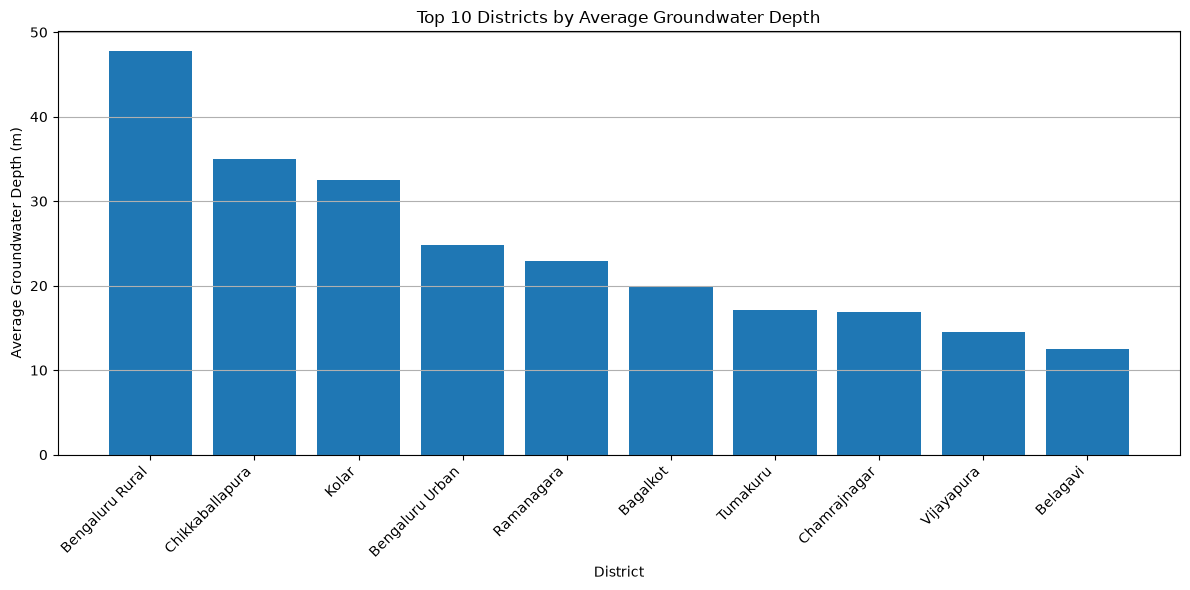

In [105]:
top_10_deepest = district_groundwater.head(10)

plt.figure(figsize=(12, 6))

plt.bar(
    top_10_deepest.index,
    top_10_deepest["mean"]
)

plt.title("Top 10 Districts by Average Groundwater Depth")
plt.xlabel("District")
plt.ylabel("Average Groundwater Depth (m)")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y")

plt.tight_layout()
plt.show()

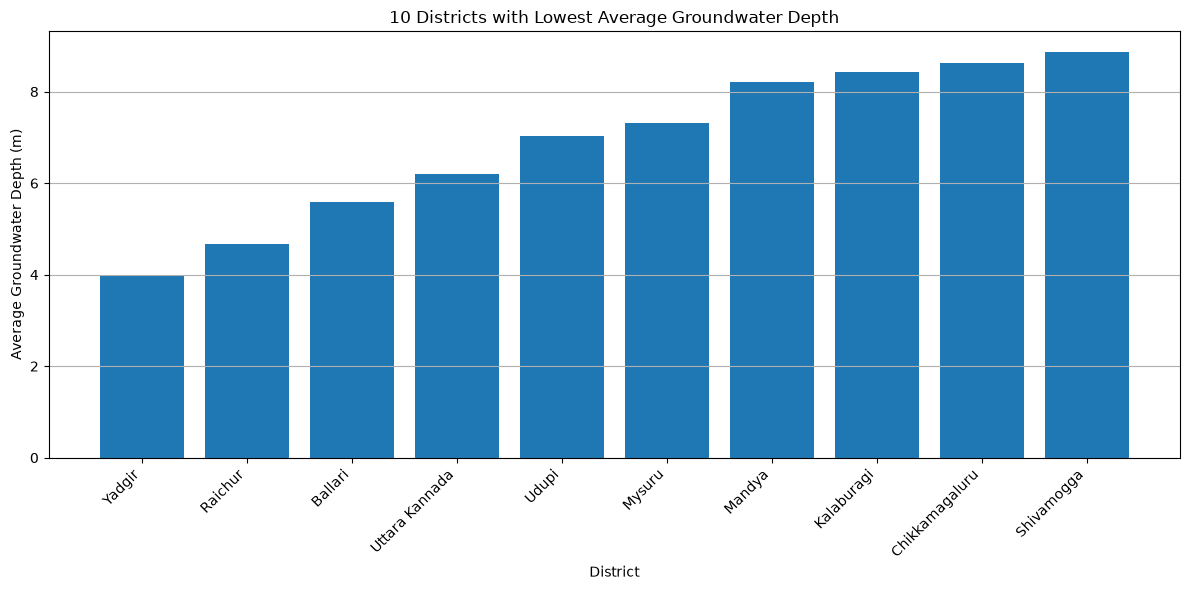

In [106]:
top_10_shallowest = district_groundwater.tail(10).sort_values(
    by="mean"
)

plt.figure(figsize=(12, 6))

plt.bar(
    top_10_shallowest.index,
    top_10_shallowest["mean"]
)

plt.title("10 Districts with Lowest Average Groundwater Depth")
plt.xlabel("District")
plt.ylabel("Average Groundwater Depth (m)")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y")

plt.tight_layout()
plt.show()

In [107]:
block_groundwater = df_clean.groupby(
    ["District", "Block"]
)["Ground Water Level"].agg(
    ["mean", "median", "min", "max", "std", "count"]
)

block_groundwater = block_groundwater.sort_values(
    by="mean",
    ascending=False
)

print(block_groundwater)

                                       mean  median   min     max        std  \
District        Block                                                          
Bengaluru Rural Devanahalli       65.803913  43.475  0.90  244.00  59.079808   
Kolar           Malur             60.433620  25.680 -0.05  265.70  65.014873   
Bengaluru Rural Hoskote           59.710231  44.915  0.34  216.00  50.324882   
Chikkaballapura Sidlaghatta       58.362754  29.550  0.30  301.30  62.478221   
                Chik Ballapur     44.968542  38.240 -0.05  235.10  44.503367   
...                                     ...     ...   ...     ...        ...   
Uttara Kannada  Karwar             3.084759   2.575  0.15   11.32   2.208167   
Kalaburagi      Kalgi              3.030091   2.800 -0.05   11.50   2.085105   
Mandya          Shrirangapattana   2.678500   2.420 -0.05    6.25   1.348362   
Yadgir          Hunasagi           2.504079   2.150 -0.05    7.55   1.466422   
                Wadagera           2.258

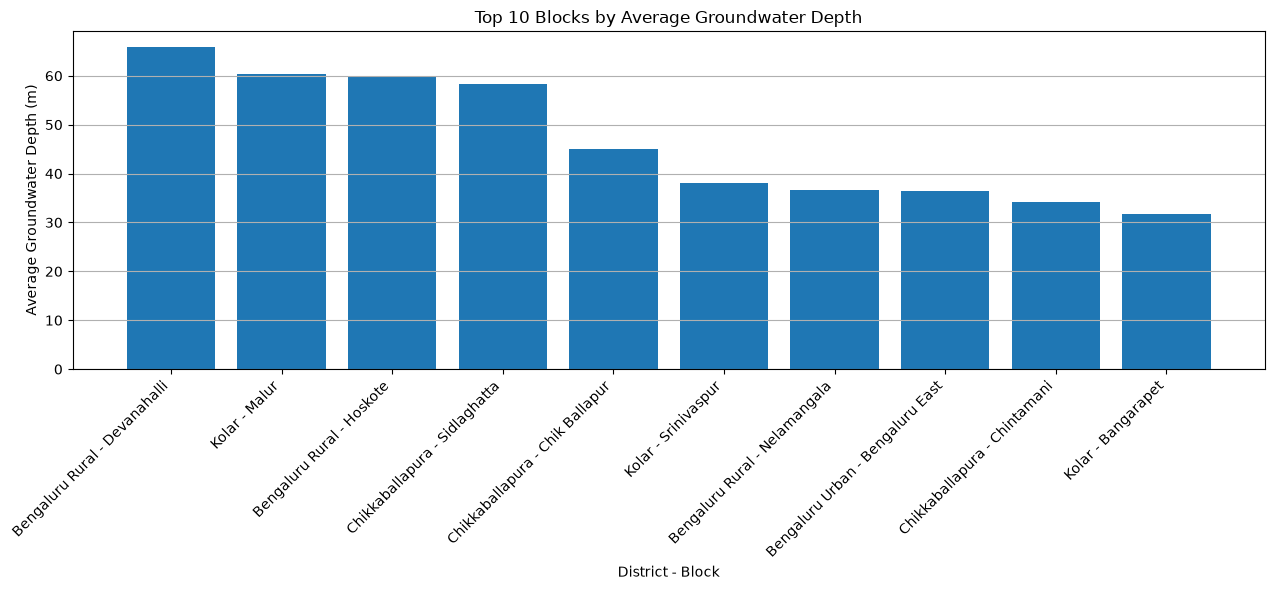

In [108]:
top_10_blocks = block_groundwater.head(10)

plt.figure(figsize=(13, 6))

plt.bar(
    top_10_blocks.index.map(lambda x: f"{x[0]} - {x[1]}"),
    top_10_blocks["mean"]
)

plt.title("Top 10 Blocks by Average Groundwater Depth")
plt.xlabel("District - Block")
plt.ylabel("Average Groundwater Depth (m)")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y")

plt.tight_layout()
plt.show()

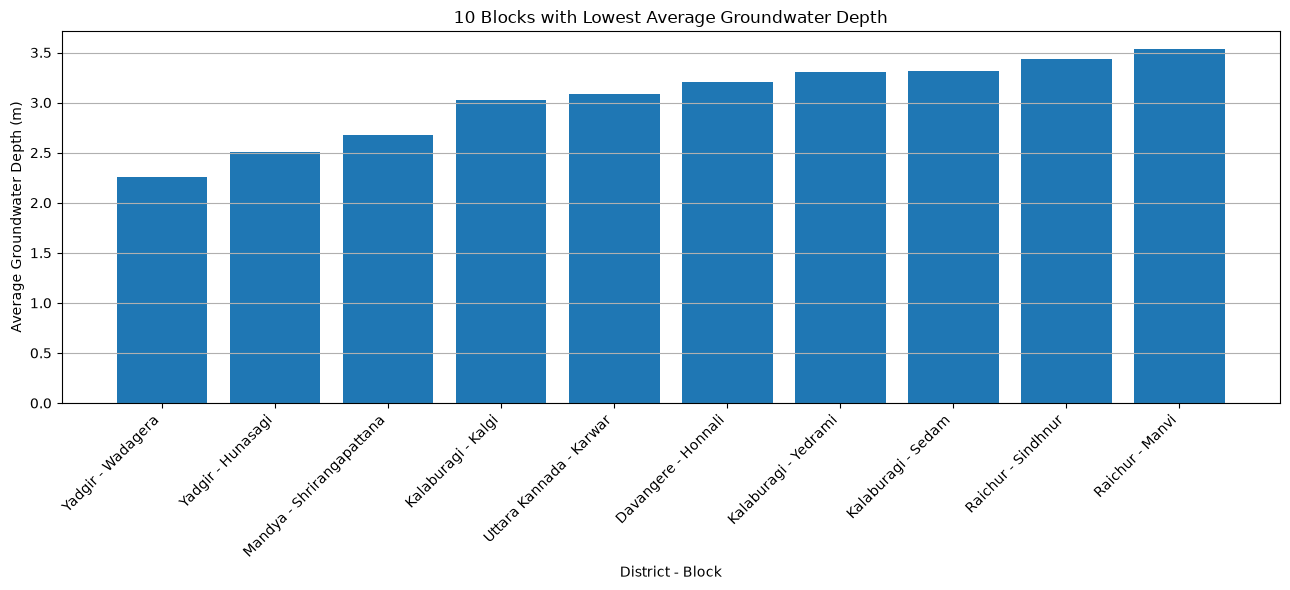

In [109]:
bottom_10_blocks = block_groundwater.tail(10).sort_values(
    by="mean"
)

plt.figure(figsize=(13, 6))

plt.bar(
    bottom_10_blocks.index.map(lambda x: f"{x[0]} - {x[1]}"),
    bottom_10_blocks["mean"]
)

plt.title("10 Blocks with Lowest Average Groundwater Depth")
plt.xlabel("District - Block")
plt.ylabel("Average Groundwater Depth (m)")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y")

plt.tight_layout()
plt.show()

In [110]:
print("TOP 10 DEEPEST BLOCKS")

print(
    top_10_blocks[
        ["mean", "median", "std", "count"]
    ]
)

print("\nTOP 10 SHALLOWEST BLOCKS")

print(
    bottom_10_blocks[
        ["mean", "median", "std", "count"]
    ]
)

TOP 10 DEEPEST BLOCKS
                                     mean  median        std  count
District        Block                                              
Bengaluru Rural Devanahalli     65.803913  43.475  59.079808   1200
Kolar           Malur           60.433620  25.680  65.014873   1207
Bengaluru Rural Hoskote         59.710231  44.915  50.324882   1278
Chikkaballapura Sidlaghatta     58.362754  29.550  62.478221   1011
                Chik Ballapur   44.968542  38.240  44.503367    806
Kolar           Srinivaspur     38.070937  22.460  46.006761   1248
Bengaluru Rural Nelamangala     36.565453  26.015  31.869337   1060
Bengaluru Urban Bengaluru East  36.505897  22.300  30.442338    312
Chikkaballapura Chintamani      34.091557  26.150  30.831654   1220
Kolar           Bangarapet      31.659306  25.770  28.270085    878

TOP 10 SHALLOWEST BLOCKS
                                     mean  median       std  count
District       Block                                              
Ya

In [111]:
block_station_count = df_clean.groupby(
    ["District", "Block"]
)["Station Code"].nunique()

print(block_station_count.sort_values(ascending=False))

District        Block     
Chikkamagaluru  Kadur         61
Hassan          Arsikere      50
Chitradurga     Challakere    47
Tumakuru        Sira          43
                Tumakuru      42
                              ..
Yadgir          Gurmatkal      2
Kalaburagi      Chitapur       2
Bidar           Hulsur         2
Koppal          Karatgi        1
Udupi           Udupi          1
Name: Station Code, Length: 236, dtype: int64


In [112]:
print("DEEPEST BLOCKS - STATION COUNTS")

print(
    block_station_count.loc[top_10_blocks.index]
)

print("\nSHALLOWEST BLOCKS - STATION COUNTS")

print(
    block_station_count.loc[bottom_10_blocks.index]
)

DEEPEST BLOCKS - STATION COUNTS
District         Block         
Bengaluru Rural  Devanahalli       26
Kolar            Malur             29
Bengaluru Rural  Hoskote           29
Chikkaballapura  Sidlaghatta       29
                 Chik Ballapur     24
Kolar            Srinivaspur       27
Bengaluru Rural  Nelamangala       23
Bengaluru Urban  Bengaluru East     9
Chikkaballapura  Chintamani        36
Kolar            Bangarapet        22
Name: Station Code, dtype: int64

SHALLOWEST BLOCKS - STATION COUNTS
District        Block           
Yadgir          Wadagera             6
                Hunasagi             8
Mandya          Shrirangapattana     5
Kalaburagi      Kalgi                4
Uttara Kannada  Karwar               9
Davangere       Honnali             10
Kalaburagi      Yedrami              2
                Sedam                5
Raichur         Sindhnur             4
                Manvi                5
Name: Station Code, dtype: int64
